# Exploratory Data Analysis — RAGTruth

News summarization subset. The plots below use the training split; the official test split is kept for final evaluation.

## 1. Load data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import GroupShuffleSplit
from sklearn.feature_extraction.text import TfidfVectorizer

responses = pd.read_json("response.jsonl", lines=True)
sources = pd.read_json("source_info.jsonl", lines=True)

## 2. Prepare data

We keep only news summaries and use RAGTruth's official train split. The official test split is saved for the final paper. We split train 80/20 into train/validation by article, so the same article never appears in both.

In [3]:
# attach each summary to its source article and keep news summaries only
df = responses.merge(sources, on="source_id")
df = df[df["task_type"] == "Summary"].copy()
df["article"] = df["source_info"]
df["summary"] = df["response"]

# label: 1 if any hallucinated span was annotated, else 0
df["hallucination"] = df["labels"].apply(len).gt(0).astype(int)

# train/validation split, grouped by article
train_pool = df[df["split"] == "train"]
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, val_idx = next(splitter.split(train_pool, groups=train_pool["source_id"]))
train = train_pool.iloc[train_idx]
val = train_pool.iloc[val_idx]

print("Train:", len(train), "| Validation:", len(val))
print("Label counts (0 = clean, 1 = hallucinated):", train_pool["hallucination"].value_counts().to_dict())

Train: 3804 | Validation: 954
Label counts (0 = clean, 1 = hallucinated): {0: 3276, 1: 1482}


## 3. Dataset overview

In [4]:

# EDA: use training data only
eda = train.copy()

print("Dataset shape:", eda.shape)
print("Unique articles:", eda["source_id"].nunique())
print("\nMissing values:")
print(eda[["article", "summary", "hallucination"]].isna().sum())

print("\nClass distribution:")
print(eda["hallucination"].value_counts())
print("\nHallucination rate:",
      round(eda["hallucination"].mean() * 100, 2), "%")

print("\nValidation hallucination rate:",
      round(val["hallucination"].mean() * 100, 2), "%")


Dataset shape: (3804, 15)
Unique articles: 634

Missing values:
article          0
summary          0
hallucination    0
dtype: int64

Class distribution:
hallucination
0    2591
1    1213
Name: count, dtype: int64

Hallucination rate: 31.89 %

Validation hallucination rate: 28.2 %


## 4. Text lengths

              article_words        summary_words        length_ratio       
                       mean median          mean median         mean median
hallucination                                                              
0                    540.32  420.0        111.34   99.0         0.23   0.23
1                    585.83  439.0        112.86  102.0         0.22   0.21


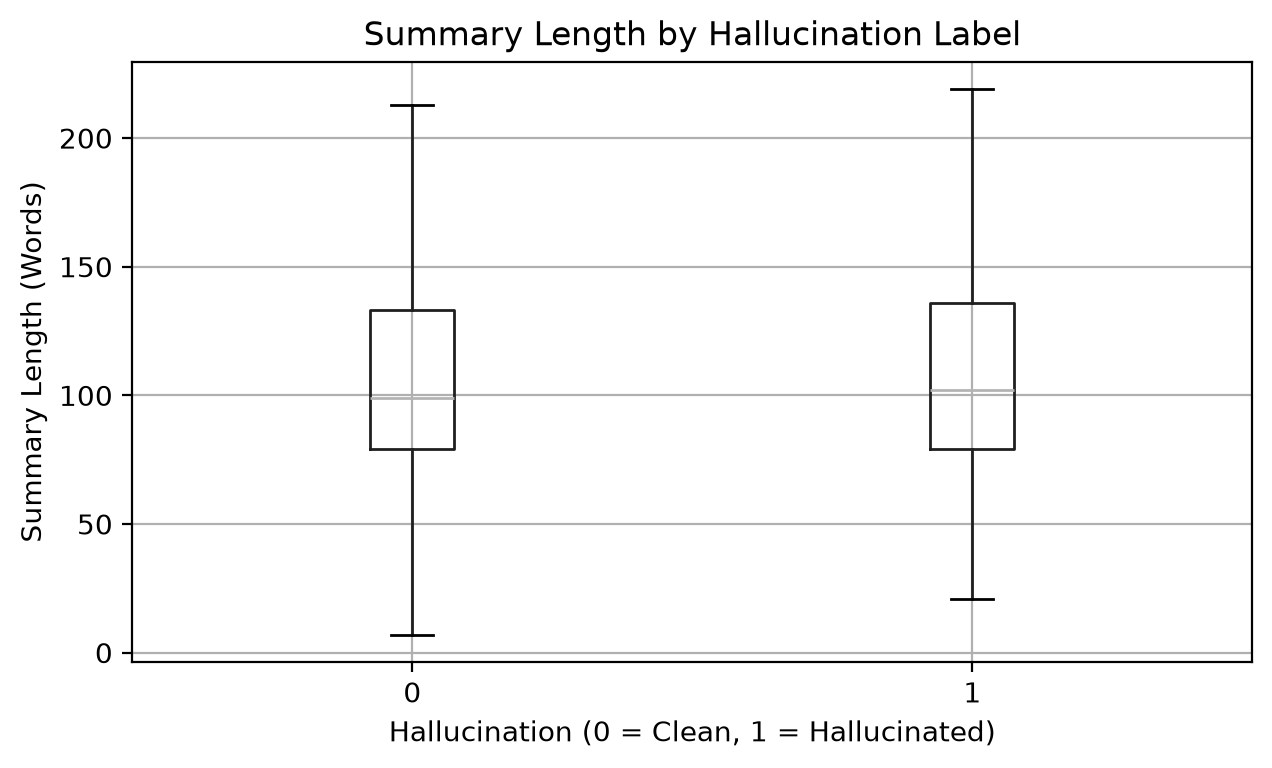

In [5]:

import matplotlib.pyplot as plt

eda["article_words"] = eda["article"].str.split().str.len()
eda["summary_words"] = eda["summary"].str.split().str.len()
eda["length_ratio"] = (
    eda["summary_words"] / eda["article_words"].clip(lower=1)
)

print(eda.groupby("hallucination")[
    ["article_words", "summary_words", "length_ratio"]
].agg(["mean", "median"]).round(2))

# Compare summary lengths by hallucination label
eda.boxplot(
    column="summary_words",
    by="hallucination",
    showfliers=False,
    figsize=(7, 4)
)
plt.title("Summary Length by Hallucination Label")
plt.suptitle("")
plt.xlabel("Hallucination (0 = Clean, 1 = Hallucinated)")
plt.ylabel("Summary Length (Words)")
plt.show()


## 5. Hallucination rate by model

['model']


,samples,hallucination_rate
model,,
mistral-7B-instruct,634,68.14
llama-2-7b-chat,634,48.42
llama-2-13b-chat,634,33.75
llama-2-70b-chat,634,24.61
gpt-4-0613,634,8.99
gpt-3.5-turbo-0613,634,7.41


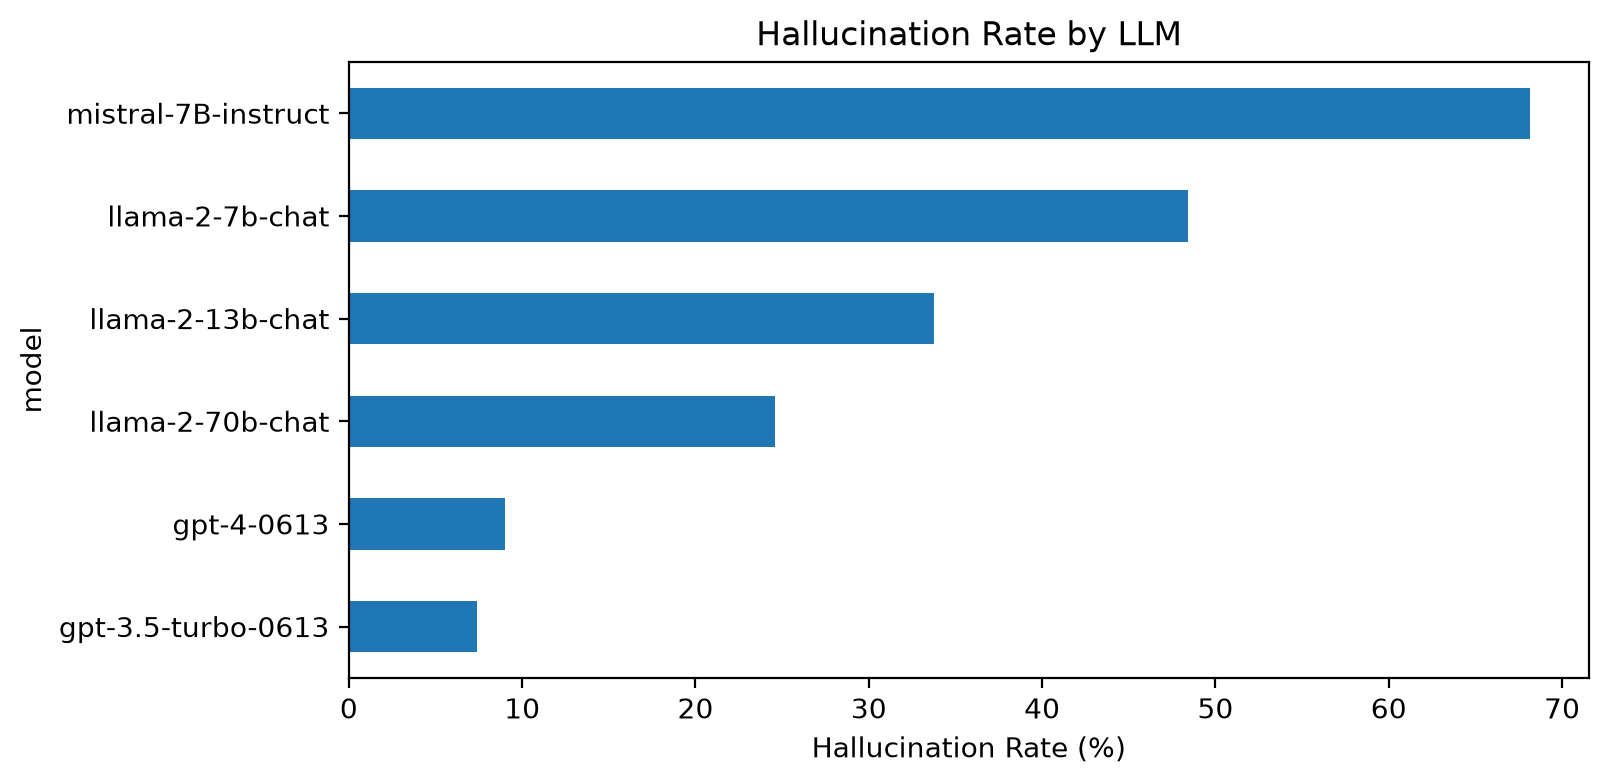

In [6]:

# Check which model-related columns are available
print([c for c in eda.columns if "model" in c.lower()])

if "model" in eda.columns:
    model_stats = eda.groupby("model").agg(
        samples=("hallucination", "size"),
        hallucination_rate=("hallucination", "mean")
    )

    model_stats["hallucination_rate"] *= 100
    display(model_stats.round(2).sort_values(
        "hallucination_rate", ascending=False
    ))

    model_stats["hallucination_rate"].sort_values().plot(
        kind="barh", figsize=(8, 4)
    )
    plt.xlabel("Hallucination Rate (%)")
    plt.title("Hallucination Rate by LLM")
    plt.show()


## 6. Temperature and hallucination

Temperature comparisons are descriptive. The sample sizes and model mix differ across temperatures.

,count,hallucination_rate
temperature,,
0.700,1724,23.72
0.775,173,88.44
0.850,188,90.43
0.925,143,93.01
1.000,1576,22.08


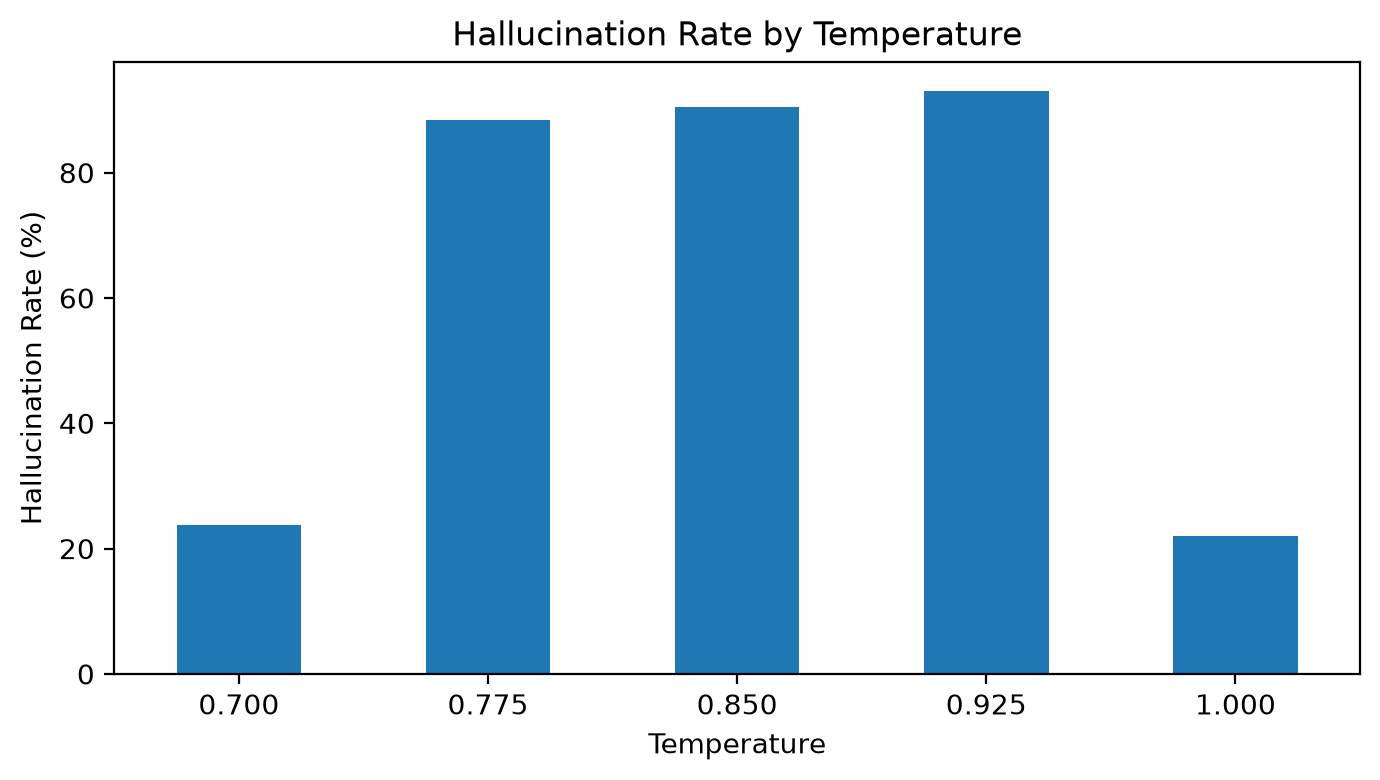

In [7]:
eda["temperature"] = pd.to_numeric(eda["temperature"], errors="coerce")

temp_stats = eda.groupby("temperature").agg(
    count=("hallucination", "size"),
    hallucination_rate=("hallucination", "mean")
).sort_index()

temp_stats["hallucination_rate"] *= 100
display(temp_stats.round(2))

ax = temp_stats["hallucination_rate"].plot(kind="bar", figsize=(7, 4))
ax.set_title("Hallucination Rate by Temperature")
ax.set_xlabel("Temperature")
ax.set_ylabel("Hallucination Rate (%)")
ax.set_xticklabels([f"{x:.3f}" for x in temp_stats.index], rotation=0)
plt.tight_layout()
plt.show()

### Temperature by model

In [8]:
# temperature by models

temp_model_stats = eda.groupby(["model", "temperature"]).agg(
    samples=("hallucination", "size"),
    hallucination_rate=("hallucination", "mean")
).reset_index()

temp_model_stats["hallucination_rate"] *= 100
display(temp_model_stats.round(2))


,model,temperature,samples,hallucination_rate
0,gpt-3.5-turbo-0613,0.70,634,7.41
1,gpt-4-0613,0.70,634,8.99
2,llama-2-13b-chat,0.70,100,65.00
3,llama-2-13b-chat,0.78,25,92.00
4,llama-2-13b-chat,0.85,40,90.00
5,llama-2-13b-chat,0.92,22,81.82
6,llama-2-13b-chat,1.00,447,16.11
7,llama-2-70b-chat,0.70,89,46.07
8,llama-2-70b-chat,0.78,19,89.47
9,llama-2-70b-chat,0.85,16,100.00


The `quality` column is almost always `good`, and `task_type` is always `Summary` after filtering. Neither adds much to this EDA.

## 7. Summary length groups

,count,hallucination_rate
length_group,,
"(6.999, 79.0]",978,31.70
"(79.0, 100.0]",958,28.50
"(100.0, 134.0]",922,34.49
"(134.0, 351.0]",946,32.98


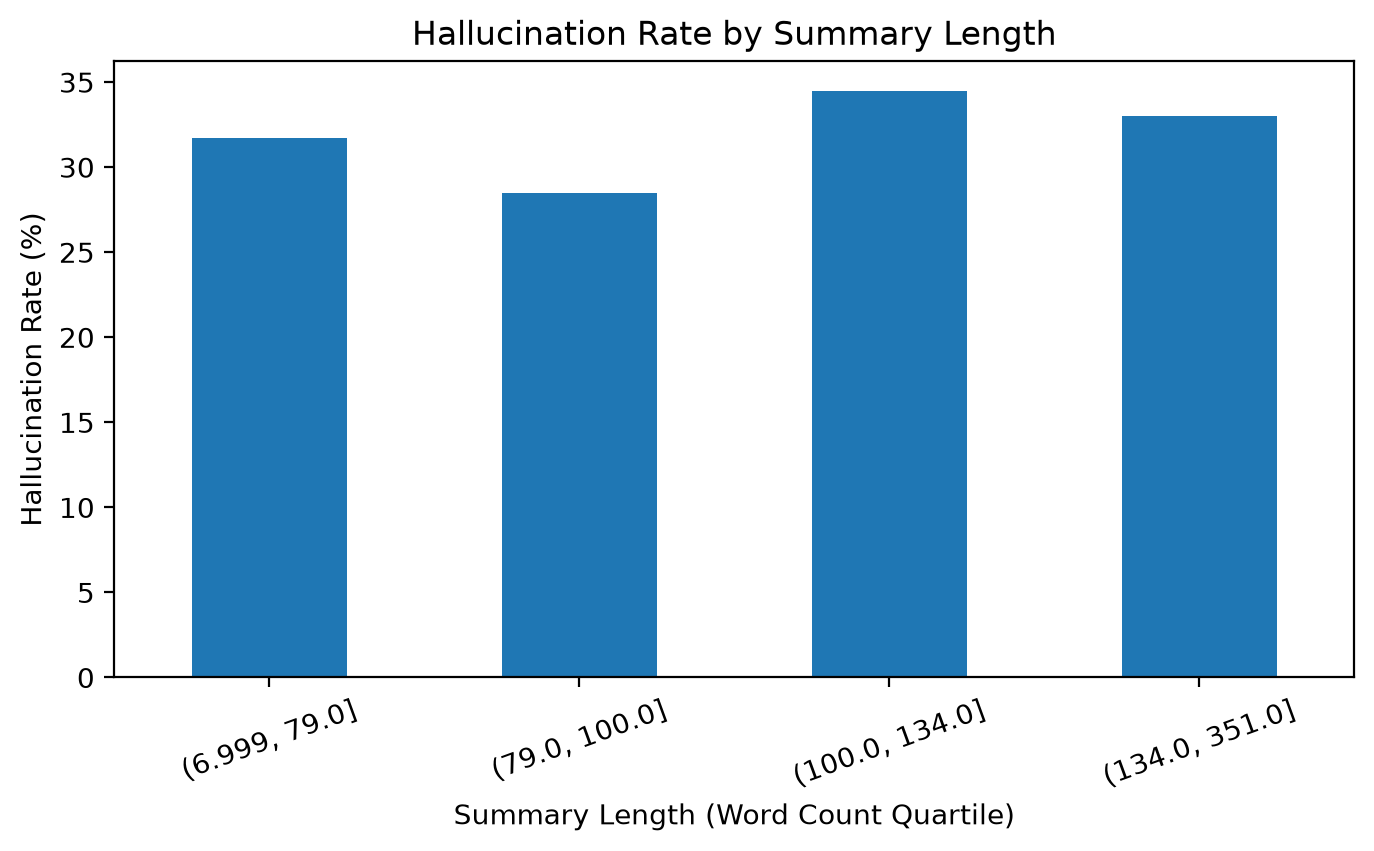

In [9]:

eda["length_group"] = pd.qcut(
    eda["summary_words"],
    q=4,
    duplicates="drop"
)

length_stats = eda.groupby(
    "length_group", observed=True
).agg(
    count=("hallucination", "size"),
    hallucination_rate=("hallucination", "mean")
)

length_stats["hallucination_rate"] *= 100
display(length_stats.round(2))

length_stats["hallucination_rate"].plot(
    kind="bar", figsize=(8, 4)
)
plt.title("Hallucination Rate by Summary Length")
plt.xlabel("Summary Length (Word Count Quartile)")
plt.ylabel("Hallucination Rate (%)")
plt.xticks(rotation=20)
plt.show()


## 8. Dataset source

Check whether the observed rate differs between the source datasets.

In [10]:
# Compare dataset sources, if they are recorded as categories
source_names = eda["source"].astype(str)
if source_names.nunique() <= 10:
    source_stats = (
        eda.assign(source_name=source_names)
        .groupby("source_name")
        .agg(samples=("hallucination", "size"),
             hallucination_rate=("hallucination", "mean"))
    )
    source_stats["hallucination_rate"] *= 100
    display(source_stats.round(2))
else:
    print("Skipping source breakdown: 'source' is not a small set of categories.")

,samples,hallucination_rate
source_name,,
CNN/DM,2484,33.25
Recent News,1320,29.32


## 9. TF-IDF similarity

This checks whether our existing word-overlap feature differs between clean and hallucinated summaries.

TF-IDF cosine similarity by label:


,mean,median,std
hallucination,,,
0,0.619,0.627,0.115
1,0.579,0.586,0.118


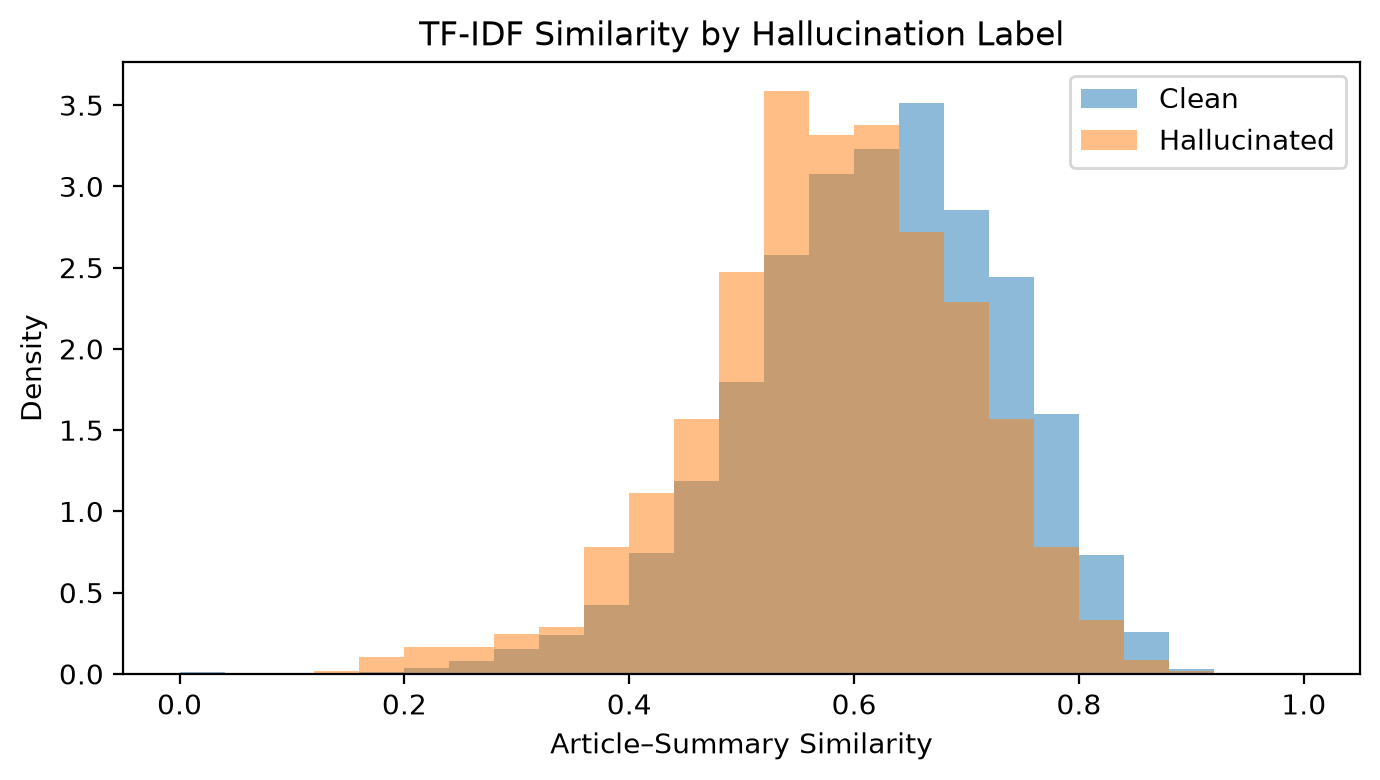

In [11]:
# Same TF-IDF settings as the logistic-regression baseline
vectorizer = TfidfVectorizer(stop_words="english", max_features=10000)
vectorizer.fit(pd.concat([train["article"], train["summary"]]))

article_vecs = vectorizer.transform(eda["article"])
summary_vecs = vectorizer.transform(eda["summary"])
eda["tfidf_similarity"] = np.asarray(
    article_vecs.multiply(summary_vecs).sum(axis=1)
).ravel()

print("TF-IDF cosine similarity by label:")
display(
    eda.groupby("hallucination")["tfidf_similarity"]
    .agg(["mean", "median", "std"]).round(3)
)

plt.figure(figsize=(7, 4))
for label, name in [(0, "Clean"), (1, "Hallucinated")]:
    plt.hist(
        eda.loc[eda["hallucination"] == label, "tfidf_similarity"],
        bins=25, range=(0, 1), alpha=0.5, density=True, label=name
    )
plt.title("TF-IDF Similarity by Hallucination Label")
plt.xlabel("Article–Summary Similarity")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

## 10. Train / validation / test overlap

In [12]:
# Check article overlap, rather than just row overlap
train_sources = set(train["source_id"])
val_sources = set(val["source_id"])
test_sources = set(df.loc[df["split"] == "test", "source_id"])

print("Train / validation shared articles:", len(train_sources & val_sources))
print("Train / test shared articles:", len(train_sources & test_sources))
print("Validation / test shared articles:", len(val_sources & test_sources))

summaries_per_article = eda.groupby("source_id").size()
print("\nSummaries per article (min / median / max):",
      summaries_per_article.min(),
      summaries_per_article.median(),
      summaries_per_article.max())

Train / validation shared articles: 0
Train / test shared articles: 0
Validation / test shared articles: 0

Summaries per article (min / median / max): 6 6.0 6


## Main observations

- **Class balance:** 31.9% of training summaries have at least one annotated hallucination (1,213 of 3,804).
- **Length:** Hallucinated summaries are only slightly longer on average (112.9 vs. 111.3 words); length alone does not appear to distinguish the labels well.
- **Models:** Hallucination rates vary substantially across generators in this subset (7.4% for GPT-3.5, 9.0% for GPT-4, and 68.1% for Mistral-7B).
- **Temperature:** Rates are high at intermediate temperatures (0.775–0.925) but much lower at 1.0. This is not evidence that raising the temperature reduces hallucinations; the groups differ in model composition and sample size.
- source: CNN/DM summaries are hallucinated a bit more often than Recent News (33.3% vs 29.3%).
- TF-IDF similarity: hallucinated summaries overlap slightly less with the article (0.58 vs 0.62 mean), but the distributions mostly overlap, so word overlap alone is a weak signal.
- splits: no article appears in more than one of train, val, and test.

These findings describe the dataset, not how the models perform on unseen articles.